# Lensed CMB skies → contrastive views

A walkthrough of the two-stage pipeline for contrastive learning on CMB maps with
real (map-level) lensing, ISW, anisotropic noise and the Planck mask.

The key idea is to split every ingredient by **which frame it lives in**:

| Ingredient | Frame | Where it happens |
|---|---|---|
| Primary CMB + ISW | sky | Stage 1 (offline, once per universe) |
| Lensing (φ field + remapping) | sky | Stage 1 |
| Random rotation | — | Stage 2 (per view) — rotates the *sky* only |
| Beam | instrument (isotropic, commutes with rotation) | Stage 2 |
| Anisotropic noise | instrument, fixed in Galactic/ecliptic coords | Stage 2, fresh draw per view |
| Mask | Galactic, fixed | Stage 2, applied last |

**Stage 1** stores full-sky, noiseless, unmasked, *lensed* T/E/B alms — one file per
universe.

**Stage 2** turns one stored sky into as many views as you like:
`rotate(alm) → beam → alm2map → + noise → × mask`.

Two views of the same universe form a positive pair. They share the CMB and lensing
realisation. They differ in orientation, which part of the sky the mask hides, and the
noise realisation.

Only a handful of ΛCDM universes are made here. This notebook is for following the
process, not for production.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "8")

import time
import warnings
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import healpy as hp
import matplotlib.pyplot as plt
import camb
import ducc0
import lenspyx
from lenspyx.utils_hp import almxfl
from scipy.spatial.transform import Rotation

from skysimulation import new_resolution_mask
from skysimulation.pipeline import lhc_lcdm_6d

warnings.filterwarnings("ignore", message=".*verbose.*")
print("camb", camb.__version__, "| healpy", hp.__version__,
      "| lenspyx", lenspyx.__version__, "| ducc0", ducc0.__version__)

camb 1.6.6 | healpy 1.19.0 | lenspyx 2.0.52 | ducc0 0.41.0


## Configuration

Resolution, beam and noise level match the existing `generate_sims_parallel.py` sims:
nside 256, 5′ beam and 40 µK·arcmin in T. The noise here is anisotropic (see Stage 2),
normalised so that its **sky-averaged** variance equals that white-noise level.

`LMAX_UNL` is larger than `LMAX_MAP` on purpose. Lensing moves power between scales,
so unlensed modes above `LMAX_MAP` feed lensed modes below it. B-modes are the most
sensitive to this: with a +1024 buffer the lensed BB came out ~2% low at ℓ≈700, while
+2048 matches CAMB to better than 0.5%. The remapping is done on a finer grid
(`NSIDE_LENS`) before going back to alms at `LMAX_MAP`. Going to nside 2048 changed
nothing.

In [2]:
NSIDE      = 256
LMAX_MAP   = 3 * NSIDE - 1          # 767 — band limit of the stored / output alms
LMAX_UNL   = LMAX_MAP + 2048        # unlensed band limit (lensing buffer; +1024 left BB ~2% low at ℓ~700)
NSIDE_LENS = 1024                   # grid the lensed sky is evaluated on
NTHREADS   = int(os.environ["OMP_NUM_THREADS"])

FWHM_ARCMIN      = 5.0
NOISE_UKARCMIN_T = 40.0
NOISE_UKARCMIN_P = 40.0 * np.sqrt(2)

N_SIMS    = 6
BASE_SEED = 20260925
LHC_SEED  = 20260926

DATA_DIR = Path("/nvme/h/lchristodoulou/cmb/SkySimulation/data/Planck")
MASK_INT = DATA_DIR / "COM_Mask_CMB-common-Mask-Int_2048_R3.00.fits"
MASK_POL = DATA_DIR / "COM_Mask_CMB-common-Mask-Pol_2048_R3.00.fits"
# Optional real noise model: a HEALPix map of per-pixel T noise std (µK), Galactic
# coords, e.g. from a Planck SMICA/NPIPE half-mission difference. None -> synthetic.
NOISE_STD_MAP_PATH = None

OUT_DIR = Path("/nvme/h/lchristodoulou/data_p318/simulations/lensed_alms_demo/planck")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(OUT_DIR)

/nvme/h/lchristodoulou/data_p318/simulations/lensed_alms_demo/planck


# Stage 1 — lensed skies (offline, once per universe)

## 1a. Spectra from CAMB

We need three things from CAMB, all as raw $C_\ell$ up to `LMAX_UNL`:

* the **unlensed** TT, EE, TE (no tensors, so unlensed BB = 0);
* the **lensing potential** spectra $C_L^{\phi\phi}$, $C_L^{\phi T}$, $C_L^{\phi E}$;
* the **lensed** spectra, used only to validate the simulated maps.

`NonLinear_lens` uses halofit for the matter power sourcing $C_L^{\phi\phi}$ (the
primary CMB stays linear).

**ISW** is included automatically. CAMB's temperature source contains both the early
and late ISW terms by default, so it's already in the unlensed TT. $C_L^{\phi T}$ is the
cross-correlation between the late-time ISW and the lensing potential: both are
sourced by the same large-scale structure. Drawing T and φ with this correlation is
what keeps the ISW–lensing link in the maps.

In [3]:
def get_spectra(p):
    # Raw C_ell (µK², φ dimensionless) up to LMAX_UNL for one parameter set p.
    pars = camb.set_params(
        H0=p["H0"], ombh2=p["ombh2"], omch2=p["omch2"], mnu=0.06, omk=0.0,
        tau=p["tau"], As=p["As"], ns=p["ns"],
        lmax=LMAX_UNL + 500, lens_potential_accuracy=1,
        NonLinear="NonLinear_lens",   # halofit C_L^φφ: non-linear structure in the lenses
    )
    res = camb.get_results(pars)
    ps  = res.get_cmb_power_spectra(pars, CMB_unit="muK", raw_cl=True, lmax=LMAX_UNL)
    unl, lpot, len_ = ps["unlensed_scalar"], ps["lens_potential"], ps["lensed_scalar"]
    return {
        "TT": unl[:, 0], "EE": unl[:, 1], "TE": unl[:, 3],       # unlensed
        "PP": lpot[:, 0], "PT": lpot[:, 1], "PE": lpot[:, 2],    # lensing potential
        "len_TT": len_[:, 0], "len_EE": len_[:, 1],              # lensed (validation)
        "len_BB": len_[:, 2], "len_TE": len_[:, 3],
    }

A handful of ΛCDM cosmologies are drawn from the same 6-D Latin hypercube as the
existing broad Planck set (`lhc_lcdm_6d`). Each universe gets its own seed, and a
`sim_id` that follows it through Stage 2.

In [4]:
params = pd.DataFrame(lhc_lcdm_6d(N_SIMS, SimpleNamespace(include_polarization=True,
                                                         tau_fixed=0.0544), LHC_SEED))
params.insert(0, "sim_id", np.arange(N_SIMS))
params["seed"] = BASE_SEED + params["sim_id"]
params

,sim_id,ombh2,omch2,H0,ns,As,tau,seed
0,0,0.021604,0.141743,67.967714,1.073590,1.503630e-09,0.029408,20260925
1,1,0.027211,0.098654,73.716734,1.047552,1.703233e-09,0.060997,20260926
2,2,0.024870,0.118835,72.043209,0.993327,2.201252e-09,0.034309,20260927
3,3,0.019055,0.103975,77.841645,1.009126,1.823799e-09,0.047890,20260928
4,4,0.021309,0.123732,62.635423,0.926588,2.016900e-09,0.093737,20260929
5,5,0.023809,0.139069,66.190865,0.963848,2.494679e-09,0.078481,20260930


In [5]:
t0 = time.time()
spectra = [get_spectra(row) for row in params.to_dict("records")]
print(f"CAMB: {time.time() - t0:.1f} s for {N_SIMS} cosmologies")

CAMB: 7.7 s for 6 cosmologies


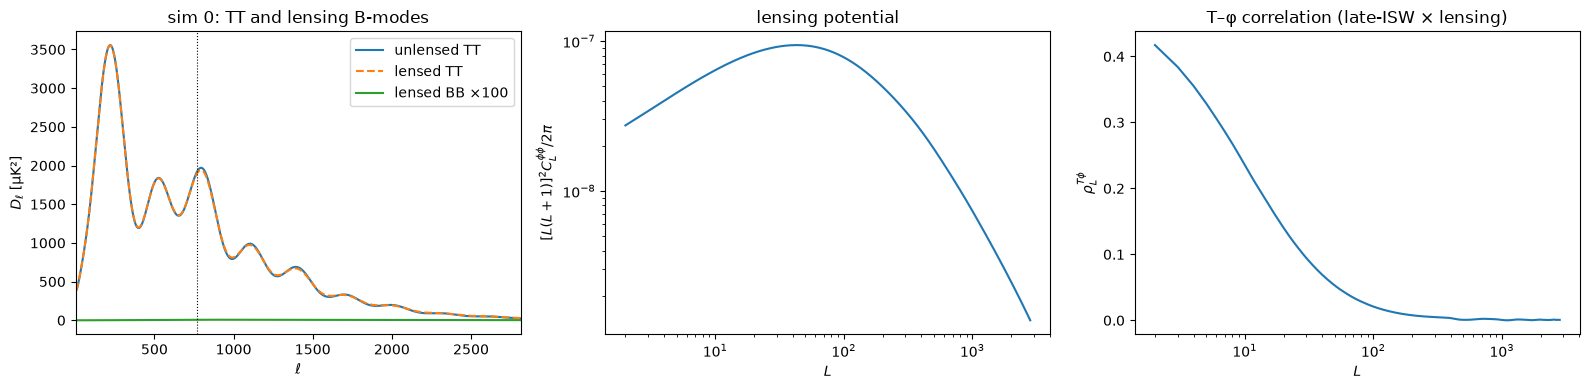

In [6]:
s = spectra[0]
L = np.arange(LMAX_UNL + 1)
dl = L * (L + 1) / (2 * np.pi)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(L, dl * s["TT"], label="unlensed TT")
ax[0].plot(L, dl * s["len_TT"], "--", label="lensed TT")
ax[0].plot(L, 100 * dl * s["len_BB"], label="lensed BB ×100")
ax[0].axvline(LMAX_MAP, color="k", lw=0.8, ls=":")
ax[0].set(xlabel=r"$\ell$", ylabel=r"$D_\ell$ [µK²]", xlim=(2, LMAX_UNL),
          title="sim 0: TT and lensing B-modes")
ax[0].legend()

ax[1].loglog(L[2:], (L * (L + 1))[2:] ** 2 * s["PP"][2:] / (2 * np.pi))
ax[1].set(xlabel=r"$L$", ylabel=r"$[L(L+1)]^2 C_L^{\phi\phi}/2\pi$",
          title="lensing potential")

rho = s["PT"][2:] / np.sqrt(s["TT"][2:] * s["PP"][2:])
ax[2].semilogx(L[2:], rho)
ax[2].set(xlabel=r"$L$", ylabel=r"$\rho_L^{T\phi}$",
          title="T–φ correlation (late-ISW × lensing)")
plt.tight_layout()

## 1b. Correlated Gaussian draw of (T, E, φ)

`hp.synalm` draws any number of correlated fields when given every auto- and
cross-spectrum. With `new=True` the ordering for fields (T, E, φ) is diagonal-major:
`[TT, EE, φφ, TE, Eφ, Tφ]`.

In [7]:
def draw_unlensed(spec, seed):
    np.random.seed(int(seed))
    tlm, elm, plm = hp.synalm(
        [spec["TT"], spec["EE"], spec["PP"], spec["TE"], spec["PE"], spec["PT"]],
        lmax=LMAX_UNL, new=True,
    )
    return tlm, elm, plm

## 1c. Lensing with lenspyx

The deflection field is the gradient of φ. In harmonic space that's the spin-1 field
$d_{LM} = \sqrt{L(L+1)}\,\phi_{LM}$. lenspyx evaluates the unlensed T, Q, U at the
deflected positions $\hat n + \mathbf{d}(\hat n)$ exactly, using non-uniform FFTs to
accuracy `epsilon`. It also applies the parallel-transport rotation of Q/U. The result
is a lensed map on the fine `NSIDE_LENS` grid, which we take back to alms at `LMAX_MAP`.

Lensing turns part of E into B, so the stored sky has non-zero B even though the
unlensed B was zero.

In [8]:
def lens(tlm, elm, plm):
    ells = np.arange(LMAX_UNL + 1, dtype=float)
    dlm = almxfl(plm, np.sqrt(ells * (ells + 1)), None, False)
    T, Q, U = lenspyx.alm2lenmap([tlm, elm], dlm,
                                 geometry=("healpix", {"nside": NSIDE_LENS}),
                                 epsilon=1e-6, nthreads=NTHREADS)
    tlm_len, elm_len, blm_len = hp.map2alm([T, Q, U], lmax=LMAX_MAP, pol=True, iter=3)
    return tlm_len, elm_len, blm_len


def sky_path(sim_id):
    return OUT_DIR / f"lensed_alm_planck_nside{NSIDE}_{int(sim_id):04d}.npz"


def make_sky(row, spec):
    # Stage 1 for one universe: draw -> lens -> save lensed TEB alms (+ φ for reference).
    path = sky_path(row["sim_id"])
    if path.exists():
        return path
    tlm, elm, plm = draw_unlensed(spec, row["seed"])
    tlm_len, elm_len, blm_len = lens(tlm, elm, plm)
    np.savez(path,
             teb=np.array([tlm_len, elm_len, blm_len]).astype(np.complex64),
             plm=hp.resize_alm(plm, LMAX_UNL, LMAX_UNL, LMAX_MAP, LMAX_MAP).astype(np.complex64),
             lmax=LMAX_MAP)
    return path

In [9]:
t0 = time.time()
for row, spec in zip(params.to_dict("records"), spectra):
    t = time.time()
    make_sky(row, spec)
    print(f"sim {row['sim_id']}: {time.time() - t:5.1f} s -> {sky_path(row['sim_id']).name}")
params.to_csv(OUT_DIR / f"metadata_planck_nside{NSIDE}.csv", index=False)
print(f"total {time.time() - t0:.1f} s")

sim 0:   6.3 s -> lensed_alm_planck_nside256_0000.npz


sim 1:   6.2 s -> lensed_alm_planck_nside256_0001.npz


sim 2:   6.2 s -> lensed_alm_planck_nside256_0002.npz


sim 3:   6.2 s -> lensed_alm_planck_nside256_0003.npz


sim 4:   6.2 s -> lensed_alm_planck_nside256_0004.npz


sim 5:   6.2 s -> lensed_alm_planck_nside256_0005.npz
total 37.4 s


## 1d. Validation

1. The realised spectra of the stored lensed alms should follow CAMB's *lensed*
   spectra. The ratio is averaged over the sims and binned in ℓ, so what's left is
   cosmic-variance scatter around 1.
2. For sim 0 we redraw the unlensed sky (same seed) and map the lensing signal
   directly: lensed − unlensed T, and the pure lensing B-mode map.

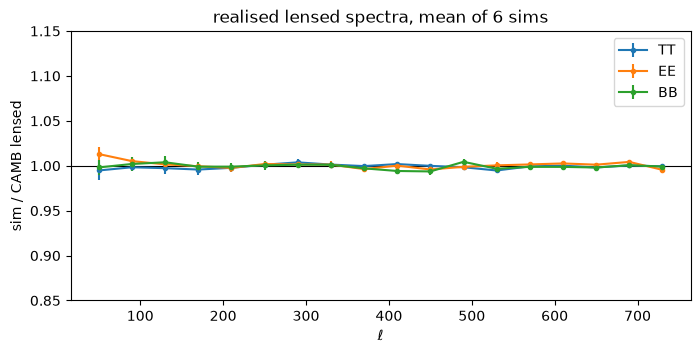

In [10]:
def load_sky(sim_id):
    with np.load(sky_path(sim_id)) as f:
        return f["teb"].astype(np.complex128)

edges = np.arange(30, LMAX_MAP + 1, 40)
centres = 0.5 * (edges[1:] + edges[:-1])
ratios = {k: [] for k in ("TT", "EE", "BB")}
for i in range(N_SIMS):
    cl = hp.alm2cl(load_sky(i))
    for j, k in enumerate(("TT", "EE", "BB")):
        with np.errstate(divide="ignore", invalid="ignore"):   # ℓ = 0, 1 are zero
            r = cl[j][: LMAX_MAP + 1] / spectra[i][f"len_{k}"][: LMAX_MAP + 1]
        ratios[k].append([r[a:b].mean() for a, b in zip(edges[:-1], edges[1:])])

fig, ax = plt.subplots(figsize=(8, 3.5))
for k, v in ratios.items():
    v = np.array(v)
    ax.errorbar(centres, v.mean(0), v.std(0) / np.sqrt(N_SIMS), fmt="o-", ms=3, label=k)
ax.axhline(1, color="k", lw=0.8)
ax.set(xlabel=r"$\ell$", ylabel="sim / CAMB lensed",
       title=f"realised lensed spectra, mean of {N_SIMS} sims", ylim=(0.85, 1.15))
ax.legend();

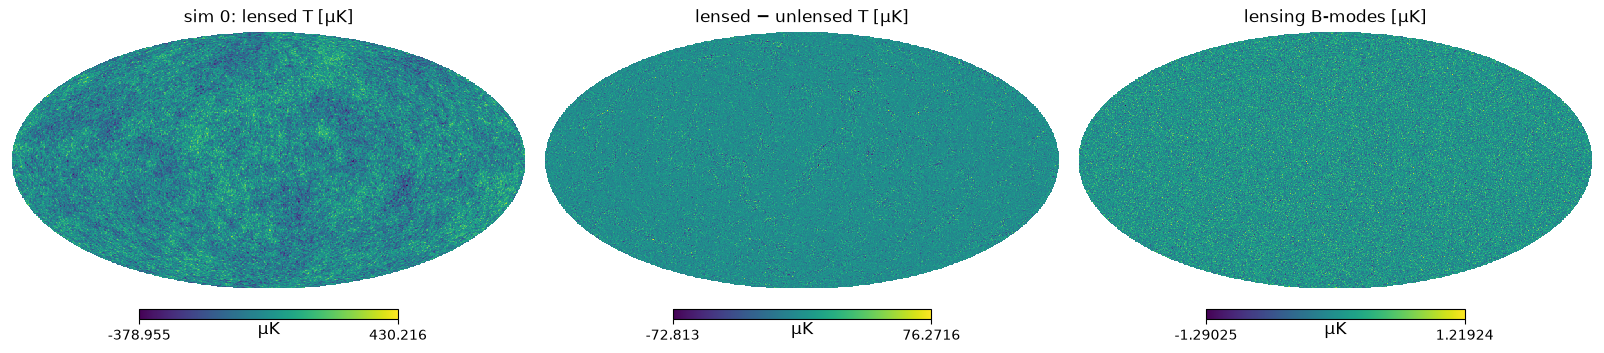

In [11]:
row0 = params.iloc[0]
tlm_u, elm_u, _ = draw_unlensed(spectra[0], row0["seed"])
tlm_u = hp.resize_alm(tlm_u, LMAX_UNL, LMAX_UNL, LMAX_MAP, LMAX_MAP)
teb0 = load_sky(0)

T_len = hp.alm2map(teb0[0], NSIDE)
T_unl = hp.alm2map(tlm_u, NSIDE)
B_len = hp.alm2map(teb0[2], NSIDE)

fig = plt.figure(figsize=(16, 3.8))
hp.mollview(T_len, sub=131, title="sim 0: lensed T [µK]", fig=fig, unit="µK")
hp.mollview(T_len - T_unl, sub=132, title="lensed − unlensed T [µK]", fig=fig, unit="µK")
hp.mollview(B_len, sub=133, title="lensing B-modes [µK]", fig=fig, unit="µK")

# Stage 2 — views (on the fly, many per universe)

## 2a. Fixed-frame ingredients

These never rotate: the mask, the noise pattern and the beam.

**Mask.** This is the same recipe as the existing sims: the Planck common masks
(Int for T, Pol for Q/U) downgraded to nside 256, binarised at 0.9 and apodised with a
2° Gaussian.

**Noise.** There's no Planck noise map on disk, so by default we build a synthetic
*scan-strategy-like* pattern. Planck scanned along great circles through the ecliptic
poles, so hit counts rise towards the poles, roughly $\propto 1/\cos\beta$ in ecliptic
latitude β, with deep regions around the poles. The per-pixel std is
$\sigma(p) \propto 1/\sqrt{\text{hits}(p)}$, normalised so the sky-averaged variance
equals the 40 µK·arcmin white-noise level. To use a real noise map, set
`NOISE_STD_MAP_PATH`.

Loading mask from /nvme/h/lchristodoulou/cmb/SkySimulation/data/Planck/COM_Mask_CMB-common-Mask-Int_2048_R3.00.fits...


Mask downgraded to nside=256. Sky fraction (f_sky): 77.20%
Loading mask from /nvme/h/lchristodoulou/cmb/SkySimulation/data/Planck/COM_Mask_CMB-common-Mask-Pol_2048_R3.00.fits...


Mask downgraded to nside=256. Sky fraction (f_sky): 77.94%


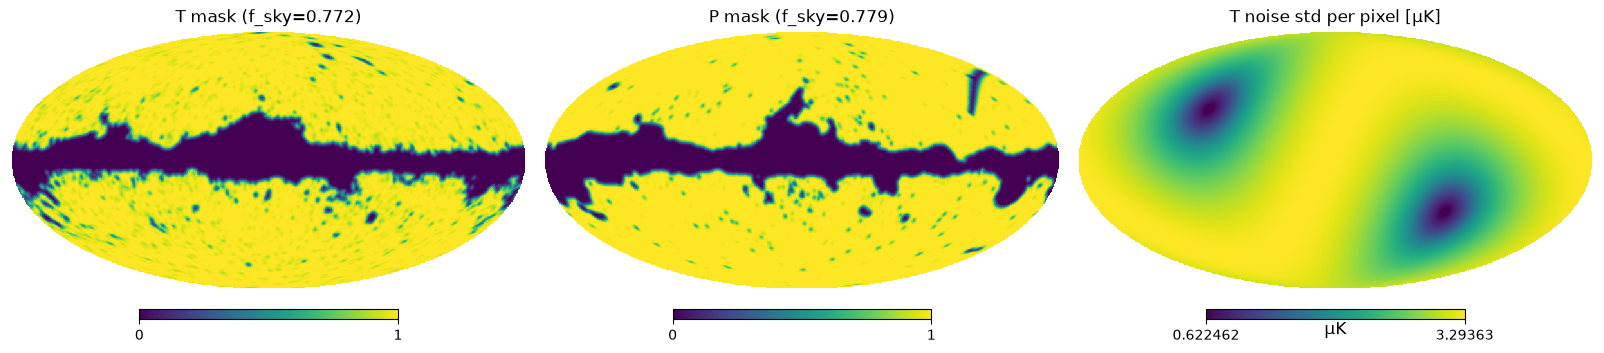

In [12]:
def build_mask(path):
    hard = new_resolution_mask(str(path), target_nside=NSIDE, threshold=0.9)
    return np.clip(hp.smoothing(hard, fwhm=np.radians(2.0)), 0.0, 1.0)

mask_T = build_mask(MASK_INT)
mask_P = build_mask(MASK_POL)

NPIX = hp.nside2npix(NSIDE)
PIX_ARCMIN = np.degrees(hp.nside2resol(NSIDE)) * 60.0

if NOISE_STD_MAP_PATH is None:
    vec_gal = np.array(hp.pix2vec(NSIDE, np.arange(NPIX)))
    vec_ecl = hp.Rotator(coord=["G", "E"])(vec_gal)
    beta = np.arcsin(np.clip(vec_ecl[2], -1, 1))                      # ecliptic latitude
    hits = 1.0 / np.maximum(np.cos(beta), 0.05)                        # great-circle scans
    hits += 8.0 * np.exp(-0.5 * ((np.pi / 2 - np.abs(beta)) / np.radians(8)) ** 2)  # deep poles
    shape = 1.0 / np.sqrt(hits)
else:
    shape = hp.ud_grade(hp.read_map(NOISE_STD_MAP_PATH), NSIDE, power=1)  # std maps: power=1
shape /= np.sqrt(np.mean(shape ** 2))                                   # <σ²> = σ0²

sigma_T = NOISE_UKARCMIN_T / PIX_ARCMIN * shape
sigma_P = NOISE_UKARCMIN_P / PIX_ARCMIN * shape

BL = hp.gauss_beam(np.radians(FWHM_ARCMIN / 60), lmax=LMAX_MAP, pol=True)  # columns T,E,B,TE

fig = plt.figure(figsize=(16, 3.8))
hp.mollview(mask_T, sub=131, title=f"T mask (f_sky={mask_T.mean():.3f})", fig=fig)
hp.mollview(mask_P, sub=132, title=f"P mask (f_sky={mask_P.mean():.3f})", fig=fig)
hp.mollview(sigma_T, sub=133, title="T noise std per pixel [µK]", fig=fig, unit="µK")

## 2b. Random rotations

A uniformly random rotation $R \in SO(3)$ comes from `scipy.spatial.transform.Rotation.random`.
We rotate in **harmonic space** with `ducc0.sht.rotate_alm`, which is:

* **exact.** There's no pixel interpolation, and E/B alms transform like scalar alms,
  so Q/U come out with the correct spin-2 behaviour automatically.
* **fast.** It takes about 0.1 s per component at lmax 767. `hp.rotate_alm` does the
  same thing but takes about 13 s for T, E and B.

The convention is checked against `hp.rotate_alm(alm, matrix=R)`. A rotated map
satisfies $m'(\hat n) = m(R^{\mathsf T}\hat n)$, so the sky point $\hat n_s$ ends up at
$R\hat n_s$.

In [13]:
def rotate_teb(teb, R):
    psi, theta, phi = R.as_euler("zyz")       # matches hp.rotate_alm(matrix=R.as_matrix())
    return np.array([ducc0.sht.rotate_alm(a, LMAX_MAP, psi, theta, phi, nthreads=NTHREADS)
                     for a in teb])

# check the convention once against healpy (slow, so only T)
R_test = Rotation.random(rng=np.random.default_rng(0))
ref = teb0[0].copy(); hp.rotate_alm(ref, matrix=R_test.as_matrix())
print("ducc vs healpy max |Δalm|:", np.abs(rotate_teb(teb0[:1], R_test)[0] - ref).max())
print("R then R⁻¹ round-trip   :", np.abs(rotate_teb(rotate_teb(teb0, R_test), R_test.inv()) - teb0).max())
print("full-sky C_ℓ preserved  :", np.allclose(hp.alm2cl(rotate_teb(teb0, R_test)), hp.alm2cl(teb0)))

ducc vs healpy max |Δalm|: 9.856004901109827e-14


R then R⁻¹ round-trip   : 9.626916072956223e-14
full-sky C_ℓ preserved  : True


## 2c. `make_view`: one stored sky → one augmented view

`rotate → beam → alm2map → + noise → × mask`, with an optional E/B from the masked
Q/U, as the existing sims do. Every stochastic choice comes from the `rng` passed in,
so a view is reproducible from `(sim_id, view_seed)`.

The output is in RING ordering, the healpy default. cmb-latent's DeepSphere code
reorders RING → NEST itself.

In [14]:
def make_view(teb, rng, rotate=True, noise=True, mask=True, eb=False):
    R = Rotation.random(rng=rng) if rotate else Rotation.identity()
    alm = rotate_teb(teb, R) if rotate else teb.copy()

    alm[0] = hp.almxfl(alm[0], BL[:, 0])
    alm[1] = hp.almxfl(alm[1], BL[:, 1])
    alm[2] = hp.almxfl(alm[2], BL[:, 2])
    T, Q, U = hp.alm2map(alm, NSIDE, pol=True)

    if noise:
        T = T + sigma_T * rng.standard_normal(NPIX)
        Q = Q + sigma_P * rng.standard_normal(NPIX)
        U = U + sigma_P * rng.standard_normal(NPIX)
    if mask:
        T, Q, U = T * mask_T, Q * mask_P, U * mask_P

    view = {"T": T, "Q": Q, "U": U, "R": R.as_matrix()}
    if eb:
        _, e, b = hp.map2alm([T, Q, U], lmax=LMAX_MAP, pol=True)
        view["E"], view["B"] = hp.alm2map(e, NSIDE), hp.alm2map(b, NSIDE)
    return view

## 2d. A positive pair and a negative

Views **A** and **B** come from the same universe (sim 0) with different rotations and
noise. View **C** comes from a different universe (sim 1). All three share the same
Galactic mask and noise pattern, since those belong to the instrument.

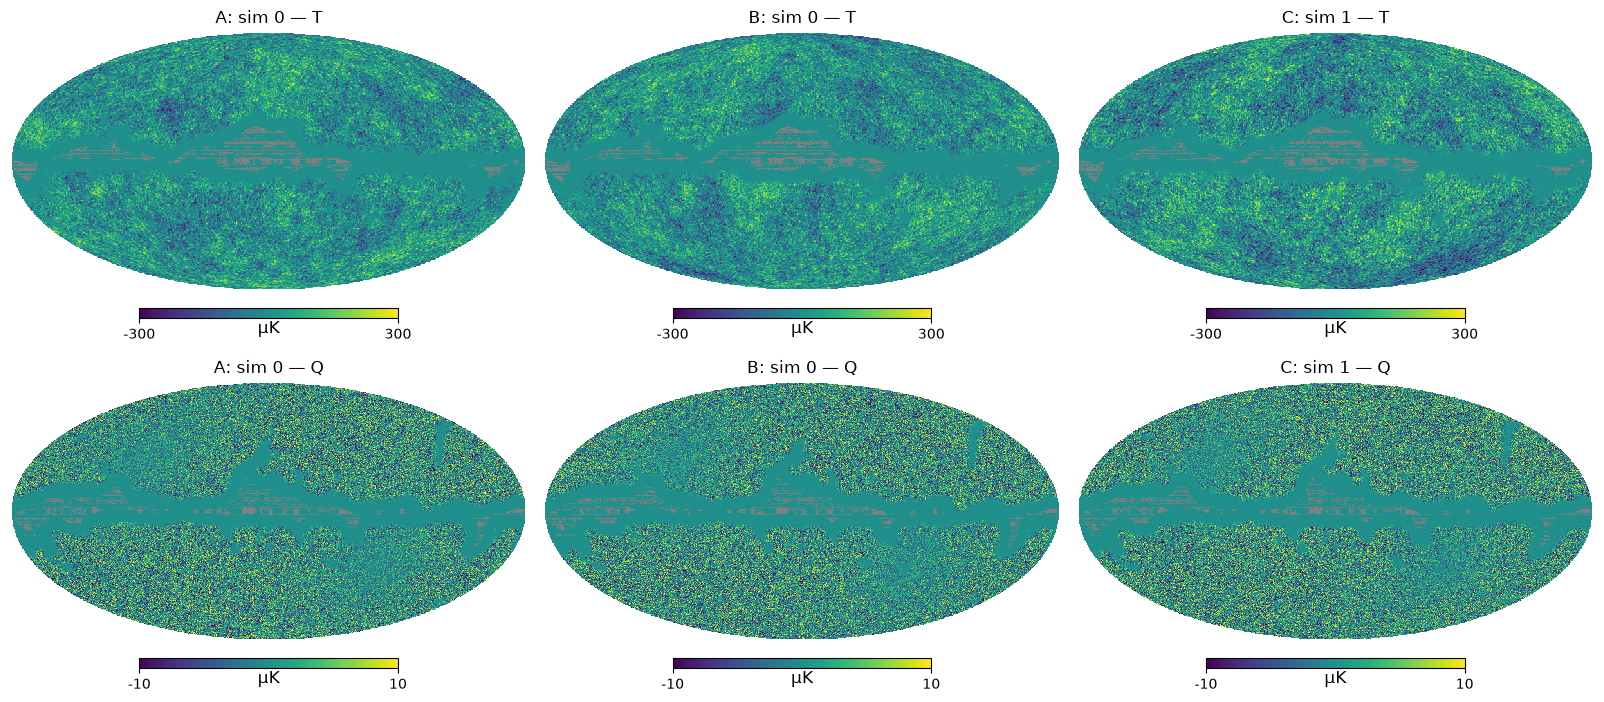

In [15]:
teb1 = load_sky(1)
rng = np.random.default_rng(123)
vA, vB = make_view(teb0, rng), make_view(teb0, rng)
vC = make_view(teb1, rng)

fig = plt.figure(figsize=(16, 7))
for k, (name, v) in enumerate([("A: sim 0", vA), ("B: sim 0", vB), ("C: sim 1", vC)]):
    hp.mollview(np.where(mask_T > 0, v["T"], hp.UNSEEN), sub=(2, 3, k + 1), fig=fig,
                title=f"{name} — T", unit="µK", min=-300, max=300)
    hp.mollview(np.where(mask_P > 0, v["Q"], hp.UNSEEN), sub=(2, 3, k + 4), fig=fig,
                title=f"{name} — Q", unit="µK", min=-10, max=10)

### What part of the universe does each view see?

Pull the mask back to the sky frame: sky point $\hat n_s$ lands at $R\hat n_s$, so it's
visible in the view if `mask(R n_s) > 0`. A and B see overlapping but different parts
of the same universe. For the network to match them, it has to recognise the universe
from *statistics*, not from particular pixels.

A sees 78.9%, B sees 78.9%, both see 63.8% of the universe


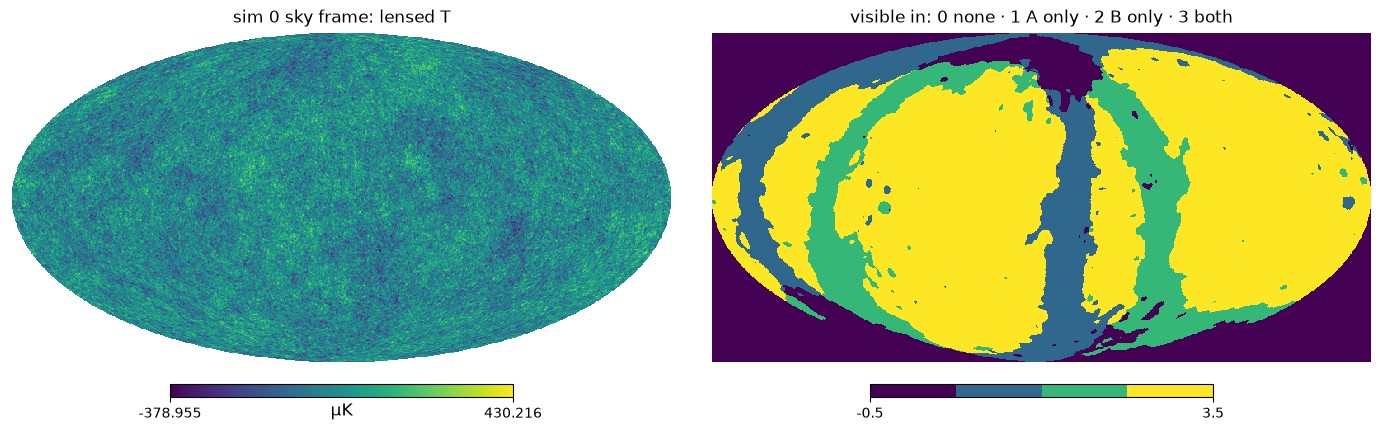

In [16]:
vec_sky = np.array(hp.pix2vec(NSIDE, np.arange(NPIX)))
def footprint_in_sky_frame(R):
    return mask_T[hp.vec2pix(NSIDE, *(R @ vec_sky))] > 0.5

fA, fB = footprint_in_sky_frame(vA["R"]), footprint_in_sky_frame(vB["R"])
overlap = fA.astype(int) + 2 * fB.astype(int)       # 0 none, 1 A only, 2 B only, 3 both
print(f"A sees {fA.mean():.1%}, B sees {fB.mean():.1%}, both see {(fA & fB).mean():.1%} of the universe")

fig = plt.figure(figsize=(14, 4))
hp.mollview(T_len, sub=121, fig=fig, title="sim 0 sky frame: lensed T", unit="µK")
hp.mollview(overlap, sub=122, fig=fig, cmap=plt.get_cmap("viridis", 4), min=-0.5, max=3.5,
            title="visible in: 0 none · 1 A only · 2 B only · 3 both")

### Pseudo-$C_\ell$ of the three views

These are rough masked spectra with no mode-coupling correction. A and B share one
universe, so their spectra should agree more closely than either does with C. A and B
also see partly different sky and different noise, so they won't match exactly. That
partial agreement is the invariance the network is being asked to learn.

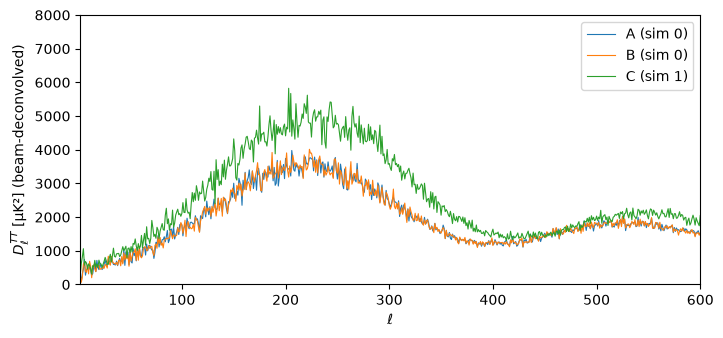

In [17]:
ell = np.arange(LMAX_MAP + 1)
fsky_T = np.mean(mask_T ** 2)
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, v in [("A (sim 0)", vA), ("B (sim 0)", vB), ("C (sim 1)", vC)]:
    cl = hp.anafast(v["T"], lmax=LMAX_MAP) / fsky_T / BL[:, 0] ** 2
    ax.plot(ell, ell * (ell + 1) * cl / (2 * np.pi), lw=0.8, label=name)
ax.set(xlabel=r"$\ell$", ylabel=r"$D_\ell^{TT}$ [µK²] (beam-deconvolved)", xlim=(2, 600), ylim=(0, 8000))
ax.legend();

## 2e. Cost per view

This is what a DataLoader worker would pay for each sample.

In [18]:
n = 10
t0 = time.time()
for _ in range(n):
    make_view(teb0, rng)
print(f"make_view: {(time.time() - t0) / n * 1e3:.0f} ms/view (T,Q,U, {NTHREADS} threads)")
t0 = time.time()
for _ in range(n):
    make_view(teb0, rng, eb=True)
print(f"make_view(eb=True): {(time.time() - t0) / n * 1e3:.0f} ms/view (T,Q,U,E,B)")

make_view: 297 ms/view (T,Q,U, 8 threads)


make_view(eb=True): 748 ms/view (T,Q,U,E,B)


## Which anomalies can the embedding capture?

With positive pairs defined as *two views of the same realisation*, the embedding is
pushed to keep whatever identifies a sky and is **invariant** to rotation, noise, mask
and (later) foreground residuals. Whether an anomaly survives therefore depends on
three questions:

* Is it **rotation-invariant**, i.e. relative rather than tied to a fixed direction?
* Is it **global**, or localised and so sometimes hidden by the mask?
* Is it defined against a **fixed frame** (ecliptic, dipole, Galactic)? Random rotations remove those frames.

| Anomaly | Type | Tied to a fixed frame? | Expected in embedding | Why / caveats |
|---|---|---|---|---|
| Low power / lack of large-angle correlation ($S_{1/2}$) | global, ℓ ≲ 30 | no | **yes** | Rotation-invariant and defined on the cut sky anyway. Limited by cosmic variance and by how large the network's receptive field is. |
| Low quadrupole | global, ℓ = 2 | no | **yes, weak** | A single number with large cosmic variance; the mask couples ℓ = 2 to neighbouring multipoles. |
| Quadrupole–octopole alignment | global, ℓ = 2, 3 | no (relative) | **yes** | The *mutual* alignment of the ℓ = 2 and ℓ = 3 multipole vectors is rotation-invariant. |
| Alignment of low multipoles with ecliptic / dipole | global | **yes** | **no** | The reference direction is fixed but the sky is randomly rotated, so the relation is destroyed. Needs a no-rotation variant. |
| Hemispherical power asymmetry (dipolar modulation) | global | amplitude no, direction yes | **amplitude yes, direction no** | The embedding can encode *how much* asymmetry, not *where* it points. The mask and anisotropic noise can mimic asymmetry, which the full-complexity views are designed to test. |
| North–south *ecliptic* asymmetry | global | **yes** | **no** (as such) | Only the frame-free part (the modulation amplitude) survives, via the row above. |
| Parity asymmetry (odd vs even low-ℓ power) | global, ℓ ≲ 30 | no | **yes** | Depends only on the power spectrum, so it's rotation-invariant. |
| Cold spot | localised, ~5–10° | location yes, shape no | **partial / uncertain** as an outlier; **better via view consistency** | Gaussian ΛCDM skies contain cold spots of every depth, so it's a *tail* event, not something unseen in training. It shows up as an outlier only if the features respond to extreme-spot depth. Both views see a given point in only ≈ f_sky² ≈ 62% of pairs, which pushes against that. The same masking, though, makes its embedding **unstable across views**, which the view-consistency test below turns into a signal. |
| Lensing amplitude ($A_L$ excess) | global, mostly ℓ ≳ 1000 | no | **weak** | Rotation-invariant, but lmax = 767 with a 5′ beam captures little of the peak smoothing. |

**Summary.** Relative, global anomalies (low power, parity, quadrupole–octopole
alignment, asymmetry amplitude) should be learnable. Anomalies defined against a
fixed direction are invisible by construction. Localised features such as the cold
spot sit in between, and are best targeted with the view-consistency test. To test each row, inject it in **Stage 1** on the primordial
(unlensed) T, *before* lensing, exactly like a physical anomaly, and check whether the injected skies become outliers relative to the ΛCDM
embedding cloud.

### Two anomaly scores

Rotation augmentation makes the **network** invariant, $f(R\,x) = f(x)$. That is not the
same as detecting violations of **statistical isotropy**. An anisotropic sky stands out
because every training sky is isotropic, not because of the invariance itself. The
invariance can still be used directly as a test:

1. **Outlier score.** How far does the sky's embedding sit from the ΛCDM embedding
   cloud? Use a density, Mahalanobis or k-nearest-neighbour distance. Best suited to
   global anomalies.
2. **View-consistency score.** Embed $M$ views of the *same* sky (e.g. $M = 100$
   random rotations, each with the fixed mask and fresh noise and residuals). Measure
   the spread of those embeddings, e.g. the trace of their covariance or the mean
   pairwise cosine distance.
   * For a ΛCDM sky the network was trained to be view-stable, so the spread is
     typical.
   * A **localised** feature that is masked in some views and visible in others
     inflates it, and so does a **directional** feature interacting with the fixed
     mask and noise.

Both scores are calibrated on ΛCDM sims generated with the same full complexity, as
an empirical p-value: the fraction of sims with a score at least as extreme. Both are
also fixed *before* looking at the real sky, which avoids the a posteriori
look-elsewhere criticism most anomaly claims face.

## Next steps

* **Dataset for contrastive training.** `__getitem__(i)` loads `lensed_alm_*_{i}.npz`
  (cache it, since each file is ~7 MB) and returns `make_view(teb, rng)` twice, stacked
  as `[npix, channels]`. Negatives come from the other universes in the batch
  (SimCLR/InfoNCE style). Give each DataLoader worker its own `rng`.
* **Choices to settle.**
  * Do positives share φ? Here they do. Redraw φ per view only if you want the
    embedding to *ignore* lensing.
  * The hemispherical family: random rotations randomise the asymmetry direction.
  * Replace the synthetic noise with a real Planck noise map.
* **Anomaly scores.** After training, compute both scores (outlier and view
  consistency) for held-out ΛCDM sims, for anomaly-injected sims (each row of the table,
  injected in Stage 1) and for the real SMICA map. Plot score distributions and
  detection rates as a function of injected amplitude.
* **Scaling up.** Stage 1 is independent per universe, so it drops straight into the
  `generate_sims_parallel.py` task-queue pattern.